In [1]:
import pandas as pd
import numpy as np
from pathlib import Path
import matplotlib.pyplot as plt
from rdkit import Chem
from rdkit.Chem import AllChem, DataStructs
from scipy.cluster import hierarchy

In [2]:
# 获取当前工作目录（即你运行代码时的目录）
current_dir = Path.cwd()
data_dir = current_dir / "data"

# 如果 data 文件夹不存在则创建
data_dir.mkdir(exist_ok=True)

# 1. 读取 SMILES 列表
smi_df = pd.read_csv(data_dir / "smi_box.csv")
smi_box = smi_df["SMILES"].tolist()
print("First row from smi_box.csv:", smi_df.iloc[0]["SMILES"])

# 2. 读取相似度矩阵
sim_df = pd.read_csv(data_dir / "similarity_matrix.csv", index_col=0)
similarity_matrix = sim_df.values.tolist()
print("First row from similarity_matrix.csv:", sim_df.iloc[0].tolist())


First row from smi_box.csv: COc1cc(C[C@H]2CO[C@H](c3ccc(O)c(OC)c3)[C@H]2CO)ccc1O
First row from similarity_matrix.csv: [0.0, 0.3170731707317073, 0.09375, 0.0451127819548872, 0.1111111111111111, 0.146788990825688, 0.1401869158878504]


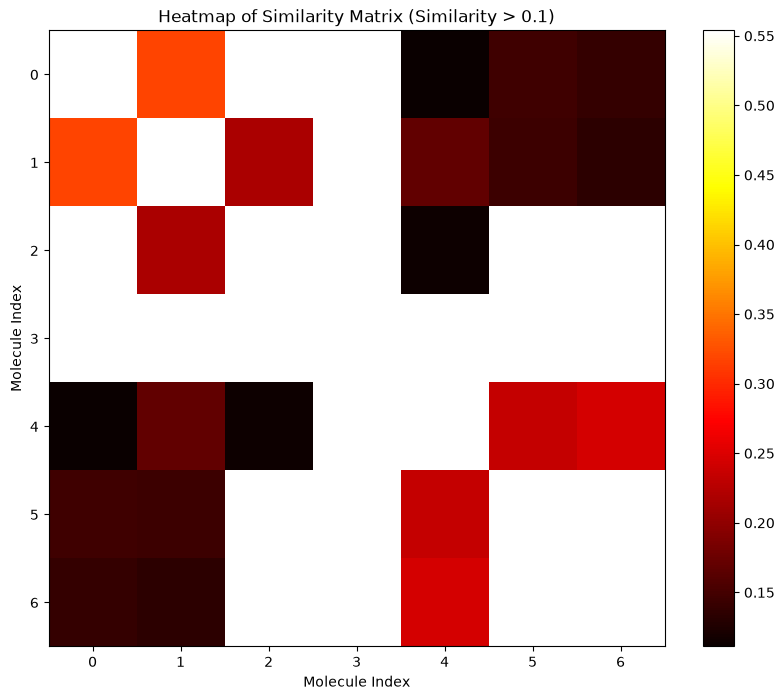

In [3]:
# 过滤相似度矩阵，保留相似度超过0.1的值，其余部分设置为NaN或透明
threshold = 0.1
filtered_matrix = np.where(np.array(similarity_matrix) > threshold, similarity_matrix, np.nan)

# 绘制热图
plt.figure(figsize=(10, 8))
plt.imshow(filtered_matrix, cmap='hot', interpolation='nearest')

# 添加颜色条
plt.colorbar()

# 添加标签
plt.xticks(range(len(smi_box)), range(len(smi_box)))
plt.yticks(range(len(smi_box)), range(len(smi_box)))
plt.xlabel('Molecule Index')
plt.ylabel('Molecule Index')
plt.title('Heatmap of Similarity Matrix (Similarity > 0.1)')

# 显示热图
plt.show()
